# Exercise 1 - Image Enhancement

## Reproducible random sample of five images

This run randomly samples five of the 20 input images using seed `20261124`. It compares Contrast Stretching, Histogram Equalization, and Gamma Transformation, then applies a separately tuned custom pipeline to each selected image. The notebook saves before/after comparisons, enhanced images, and metrics under `outputs/random_five_before_after/`.

The goal is to choose a visually appropriate enhancement for each image. Metrics support the comparison but do not replace visual inspection.

## 1. Install dependencies

Run once in the notebook environment. Restart the kernel if prompted.

In [1]:
%pip install numpy opencv-python matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports, paths, and random image selection

The notebook keeps all 20 inputs available, then selects five reproducibly with Python's random seed `20261124`. Change the seed to draw another random sample.

In [2]:
from pathlib import Path
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current = Path.cwd()
PROJECT_ROOT = next((folder for folder in (current, *current.parents)
                     if (folder / "1 Image Enhancement" / "Input").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project folder containing '1 Image Enhancement'.")

IMAGE_DIR = PROJECT_ROOT / "1 Image Enhancement" / "Input"
IMAGE_NAMES = [f"{index:02d}.jpg" for index in range(1, 21)]
SELECTION_SEED = 20261124
SELECTED_IMAGE_NAMES = sorted(random.Random(SELECTION_SEED).sample(IMAGE_NAMES, 5))
GAMMA_VALUES = (0.6, 0.75, 0.8, 0.85, 1.0, 1.2, 1.5)
LOW_PERCENTILE = 1
HIGH_PERCENTILE = 99
EQUALIZATION_STRENGTH = 1
CUSTOM_PIPELINES = {
    "01.jpg": [{"method": "gamma", "gamma": 0.85}],
    "02.jpg": [{"method": "contrast_stretch", "low_pct": 1, "high_pct": 99},
               {"method": "gamma", "gamma": 0.9}],
    "03.jpg": [{"method": "gamma", "gamma": 1.2}],
    "04.jpg": [{"method": "gamma", "gamma": 0.8}],
    "05.jpg": [{"method": "gamma", "gamma": 0.75}],
    "06.jpg": [{"method": "gamma", "gamma": 0.75}],
    "07.jpg": [{"method": "gamma", "gamma": 0.8}],
    "08.jpg": [{"method": "contrast_stretch", "low_pct": 1, "high_pct": 99}],
    "09.jpg": [{"method": "gamma", "gamma": 0.8}, {"method": "contrast_stretch", "low_pct": 1, "high_pct": 99}],
    "10.jpg": [{"method": "histogram_equalization", "strength": 0.45}],
    "11.jpg": [{"method": "gamma", "gamma": 0.9}],
    "12.jpg": [],
    "13.jpg": [{"method": "gamma", "gamma": 0.8}],
    "14.jpg": [{"method": "contrast_stretch", "low_pct": 1, "high_pct": 99}],
    "15.jpg": [{"method": "gamma", "gamma": 0.85}],
    "16.jpg": [{"method": "contrast_stretch", "low_pct": 1, "high_pct": 99}],
    "17.jpg": [{"method": "histogram_equalization", "strength": 0.45}],
    "18.jpg": [{"method": "contrast_stretch", "low_pct": 1, "high_pct": 99}],
    "19.jpg": [{"method": "contrast_stretch", "low_pct": 1, "high_pct": 99}, {"method": "gamma", "gamma": 0.9}],
    "20.jpg": [{"method": "contrast_stretch", "low_pct": 1, "high_pct": 99}, {"method": "gamma", "gamma": 0.9}],
}

if len(IMAGE_NAMES) != 20 or len(set(IMAGE_NAMES)) != 20:
    raise ValueError("Expected the 20 source images.")
missing = [name for name in IMAGE_NAMES if not (IMAGE_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f"Images not found: {missing}")
print(f"Project root: {PROJECT_ROOT}")
print(f"Random seed: {SELECTION_SEED}")
print(f"Selected images: {SELECTED_IMAGE_NAMES}")

Project root: c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei
Random seed: 20261124
Selected images: ['01.jpg', '02.jpg', '05.jpg', '06.jpg', '15.jpg']


### Manual tuning controls

Change these values in the setup cell, then rerun the notebook. LOW_PERCENTILE and HIGH_PERCENTILE control Contrast Stretching; EQUALIZATION_STRENGTH blends the original with the equalized image; GAMMA_VALUES controls the gamma results to compare. Keep the same settings across images for a fair comparison. Change one control at a time.

## 3. Reusable transformations

All three methods below accept an 8-bit grayscale image and return an 8-bit result. Contrast Stretching uses the same percentile limits for every image. Gamma values are applied to the original image, not sequentially to another transformed result.

In [3]:
def contrast_stretch(gray, low_pct=LOW_PERCENTILE, high_pct=HIGH_PERCENTILE):
    low = float(np.percentile(gray, low_pct))
    high = float(np.percentile(gray, high_pct))
    if high <= low:
        raise ValueError("The selected percentile range has no intensity span.")
    scaled = (gray.astype(np.float32) - low) / (high - low) * 255.0
    return np.clip(scaled, 0, 255).astype(np.uint8)

def histogram_equalization(gray, strength=1.0):
    if not 0.0 <= strength <= 1.0:
        raise ValueError("Equalization strength must be between 0 and 1.")
    equalized = cv2.equalizeHist(gray)
    return cv2.addWeighted(gray, 1.0 - strength, equalized, strength, 0.0)

def gamma_transform(gray, gamma):
    if gamma <= 0:
        raise ValueError("Gamma must be positive.")
    normalized = gray.astype(np.float32) / 255.0
    corrected = 255.0 * np.power(normalized, gamma)
    return np.clip(corrected, 0, 255).astype(np.uint8)

def transform_color_lightness(color_bgr, transform):
    """Apply a grayscale intensity transform to Lab lightness; preserve chroma channels."""
    lab = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    transformed_lightness = transform(lightness)
    transformed_lab = cv2.merge((transformed_lightness, channel_a, channel_b))
    transformed_bgr = cv2.cvtColor(transformed_lab, cv2.COLOR_LAB2BGR)
    return cv2.cvtColor(transformed_bgr, cv2.COLOR_BGR2RGB)

def image_metrics(gray):
    values = gray.astype(np.float32)
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    probabilities = hist / hist.sum()
    nonzero = probabilities > 0
    entropy = -np.sum(probabilities[nonzero] * np.log2(probabilities[nonzero]))
    clipped_percent = 100.0 * np.mean((gray <= 5) | (gray >= 250))
    return {
        "mean_brightness": float(values.mean()),
        "std_intensity": float(values.std()),
        "entropy_bits": float(entropy),
        "clipped_pixels_percent": float(clipped_percent),
        "min_intensity": int(gray.min()),
        "max_intensity": int(gray.max()),
    }

def apply_pipeline_gray(gray, steps):
    """Apply a list of enhancement steps in order to a grayscale image."""
    result = gray.copy()
    for step in steps:
        method = step.get("method")
        if method == "contrast_stretch":
            result = contrast_stretch(
                result,
                step.get("low_pct", LOW_PERCENTILE),
                step.get("high_pct", HIGH_PERCENTILE),
            )
        elif method == "histogram_equalization":
            result = histogram_equalization(
                result, step.get("strength", EQUALIZATION_STRENGTH)
            )
        elif method == "gamma":
            if "gamma" not in step:
                raise ValueError("Each gamma step must include a gamma value.")
            result = gamma_transform(result, step["gamma"])
        else:
            raise ValueError(f"Unknown pipeline method: {method}")
    return result

def apply_pipeline_color(color_bgr, steps):
    """Apply the same ordered pipeline to Lab lightness and retain original chroma."""
    lab = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    transformed_lightness = apply_pipeline_gray(lightness, steps)
    transformed_lab = cv2.merge((transformed_lightness, channel_a, channel_b))
    transformed_bgr = cv2.cvtColor(transformed_lab, cv2.COLOR_LAB2BGR)
    return cv2.cvtColor(transformed_bgr, cv2.COLOR_BGR2RGB)

### Choose a custom combination for each image

Each selected filename has a separately tuned ordered pipeline in `CUSTOM_PIPELINES`. A step receives the previous step's result, and color previews apply the sequence to Lab lightness so the original chroma is retained as far as the color conversion allows.

For this sample, image `02.jpg` first receives a mild contrast stretch and then a gamma adjustment. The remaining selected images use a gentler gamma step where additional contrast processing would over-brighten highlights or reveal unwanted background texture.

## Suggested starting pipelines for the 20 images

These are visual starting points based on the image set, not objectively proven optima. Review each Custom Combination beside the original and the single-method results, then adjust settings where details are lost or the image looks unnatural.

| Image | Suggested combination | Reason to try it |
|---|---|---|
| 01 | Gamma 0.85 | Lifts the shaded bird more gently while retaining the cloudy sky. |
| 02 | Contrast Stretching 1-99, then Gamma 0.9 | Expands architectural tones, then gently lifts the middle tones. |
| 03 | Gamma 1.2 | Tones down strong water highlights. |
| 04 | Gamma 0.8 | Gently lifts the dark grass and small subject. |
| 05 | Gamma 0.75 | Reveals the wolf face while retaining its rim light and dark background. |
| 06 | Gamma 0.75 | Lifts the ducks and reflections without making the reeds too bright. |
| 07 | Gamma 0.8 | Gently improves visibility of the subject against the water. |
| 08 | Contrast Stretching | Adds separation to the overcast farm scene. |
| 09 | Gamma 0.8, then Contrast Stretching | Lifts the muted scene and expands its tonal range. |
| 10 | Histogram Equalization at 0.45 strength | Tries to reveal the camouflaged lizard without applying full equalization. |
| 11 | Gamma 0.9 | Makes a subtle brightness adjustment while preserving texture. |
| 12 | No transformation | The dunes already have clear tonal structure and texture. |
| 13 | Gamma 0.8 | Gently lifts the dark underwater subject. |
| 14 | Contrast Stretching | Increases separation in the stone structure and sky. |
| 15 | Gamma 0.85 | Lifts the forest silhouette slightly while keeping the moon distinct. |
| 16 | Contrast Stretching | Adds separation among the sea, island, and foreground rocks. |
| 17 | Histogram Equalization at 0.45 strength | Tests whether the low-contrast snake becomes easier to distinguish from sand. |
| 18 | Contrast Stretching | Uses the available range in the colorful underwater scene. |
| 19 | Contrast Stretching, then Gamma 0.9 | Addresses haze and adds a mild tonal adjustment. |
| 20 | Contrast Stretching, then Gamma 0.9 | Adds separation to the desert scene with a gentle brightness correction. |

Some images may look better unchanged or with a different parameter. In particular, inspect highlights in 03, shadows in 05-07 and 13, and background texture in 10 and 17.

## 4. Process and display each selected image

For every image, the upper row shows grayscale results and the lower row shows color previews. Color previews transform Lab lightness while retaining the original chroma channels. The Custom Combination column uses the ordered per-image pipeline in CUSTOM_PIPELINES. Each step processes the result of the previous step. An empty sequence leaves the image unchanged.

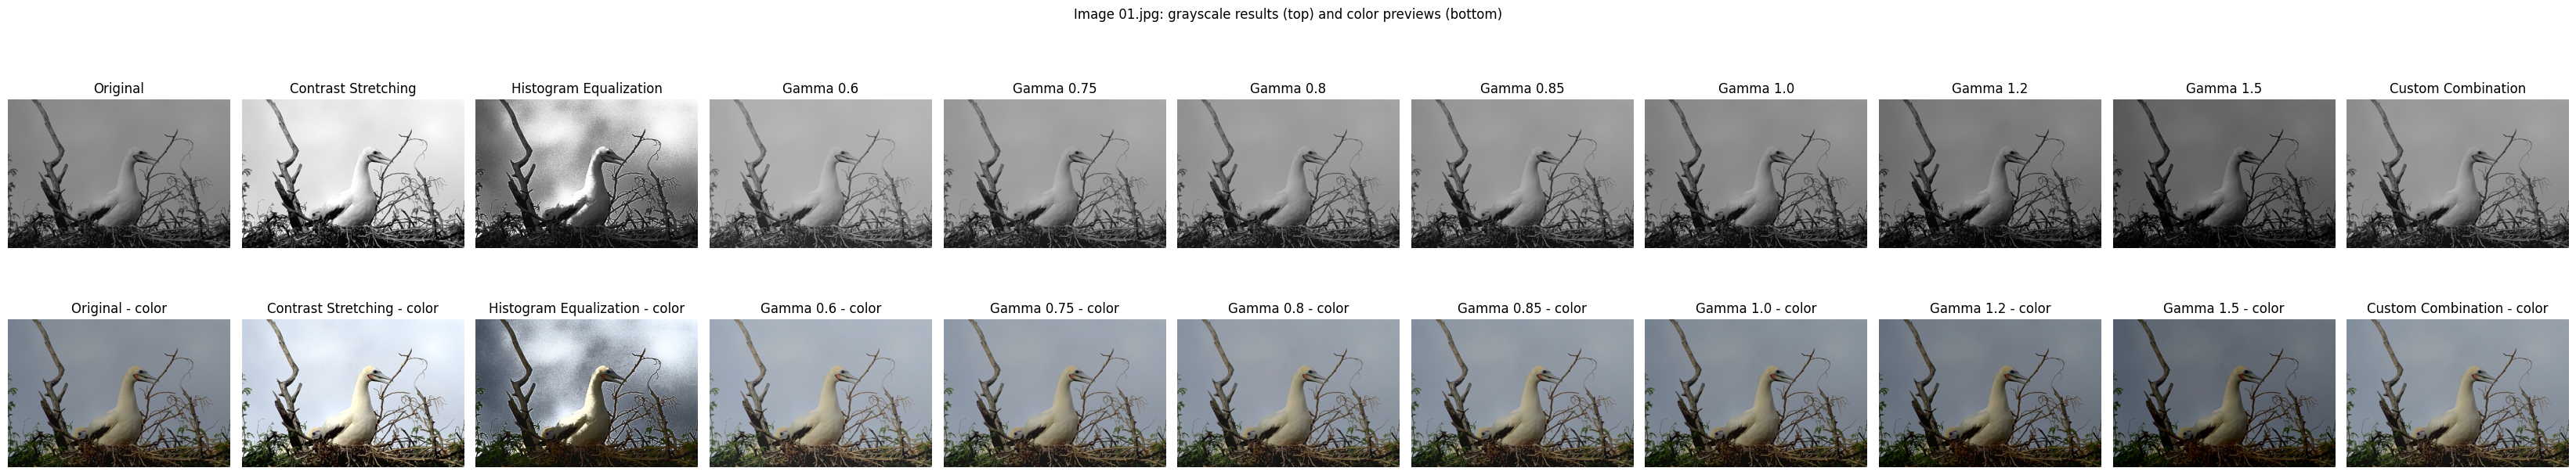

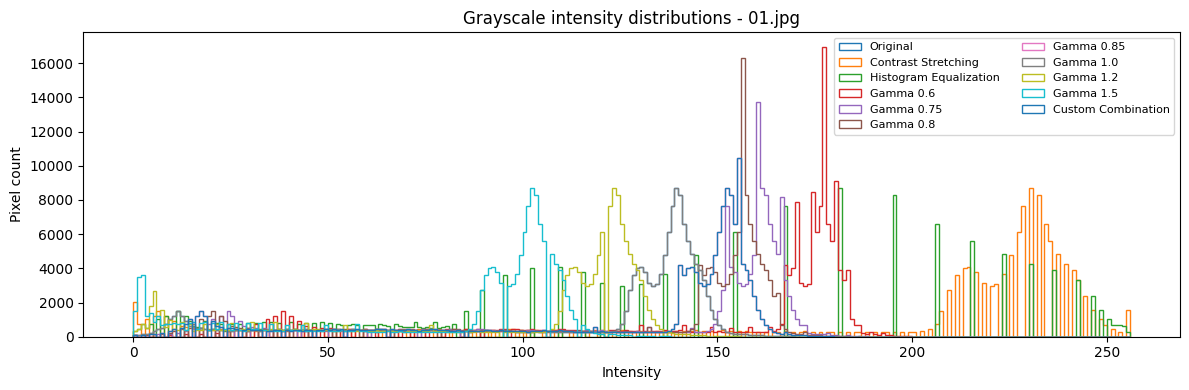

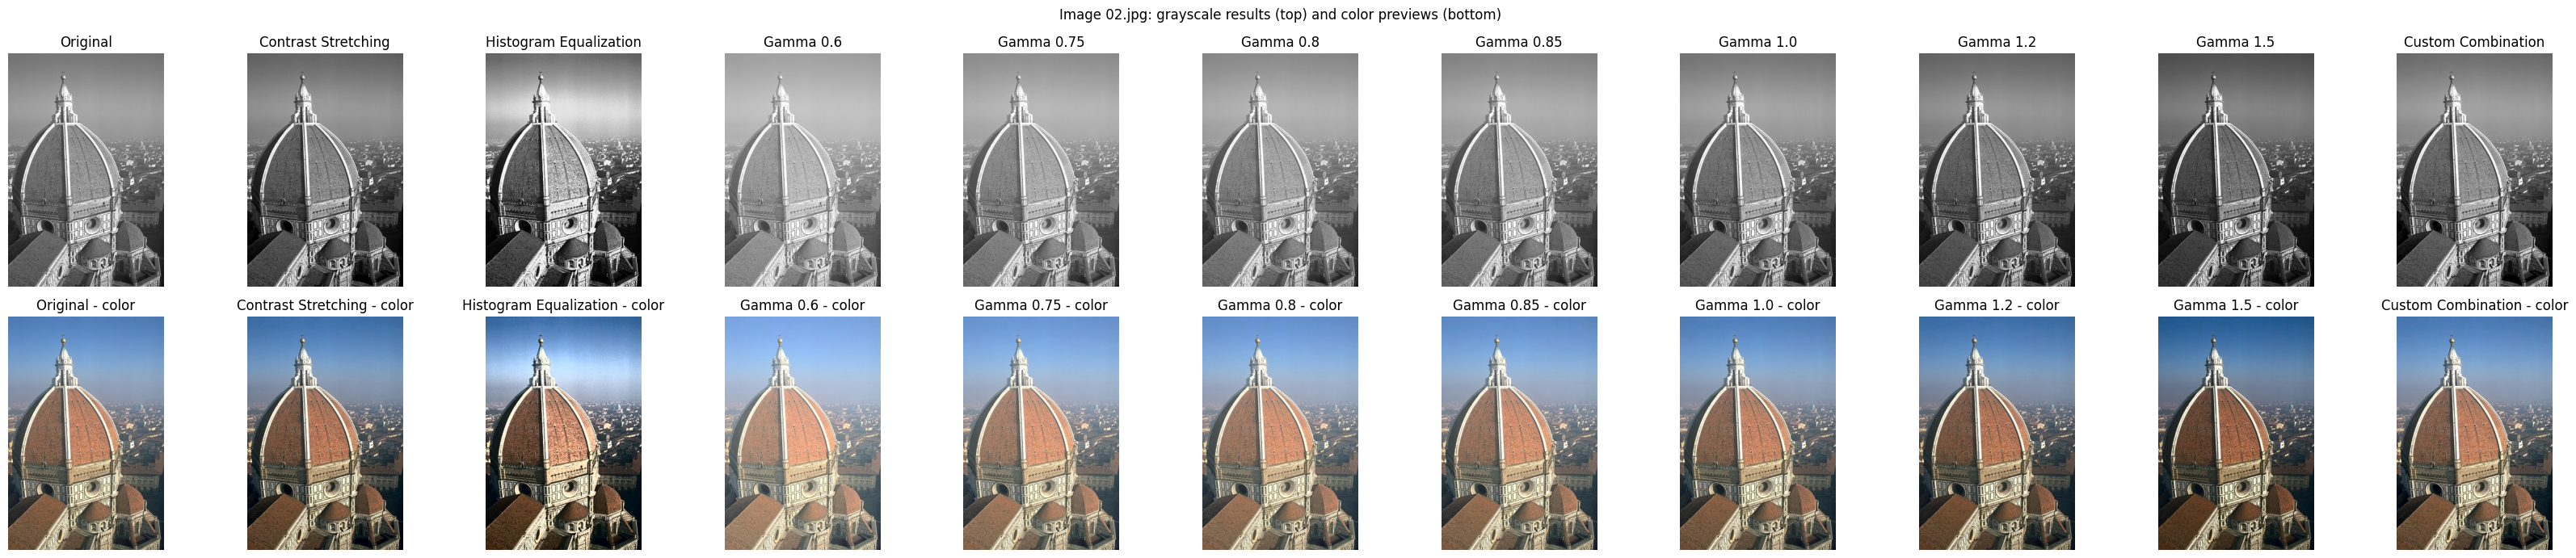

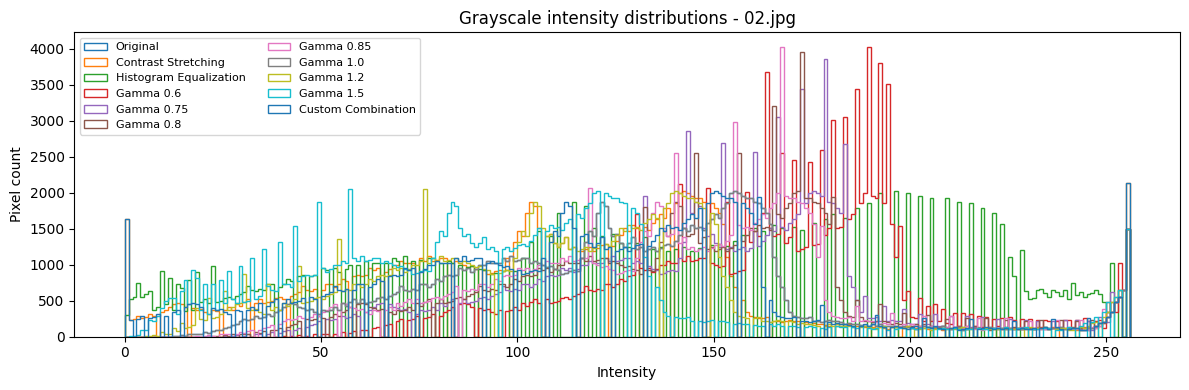

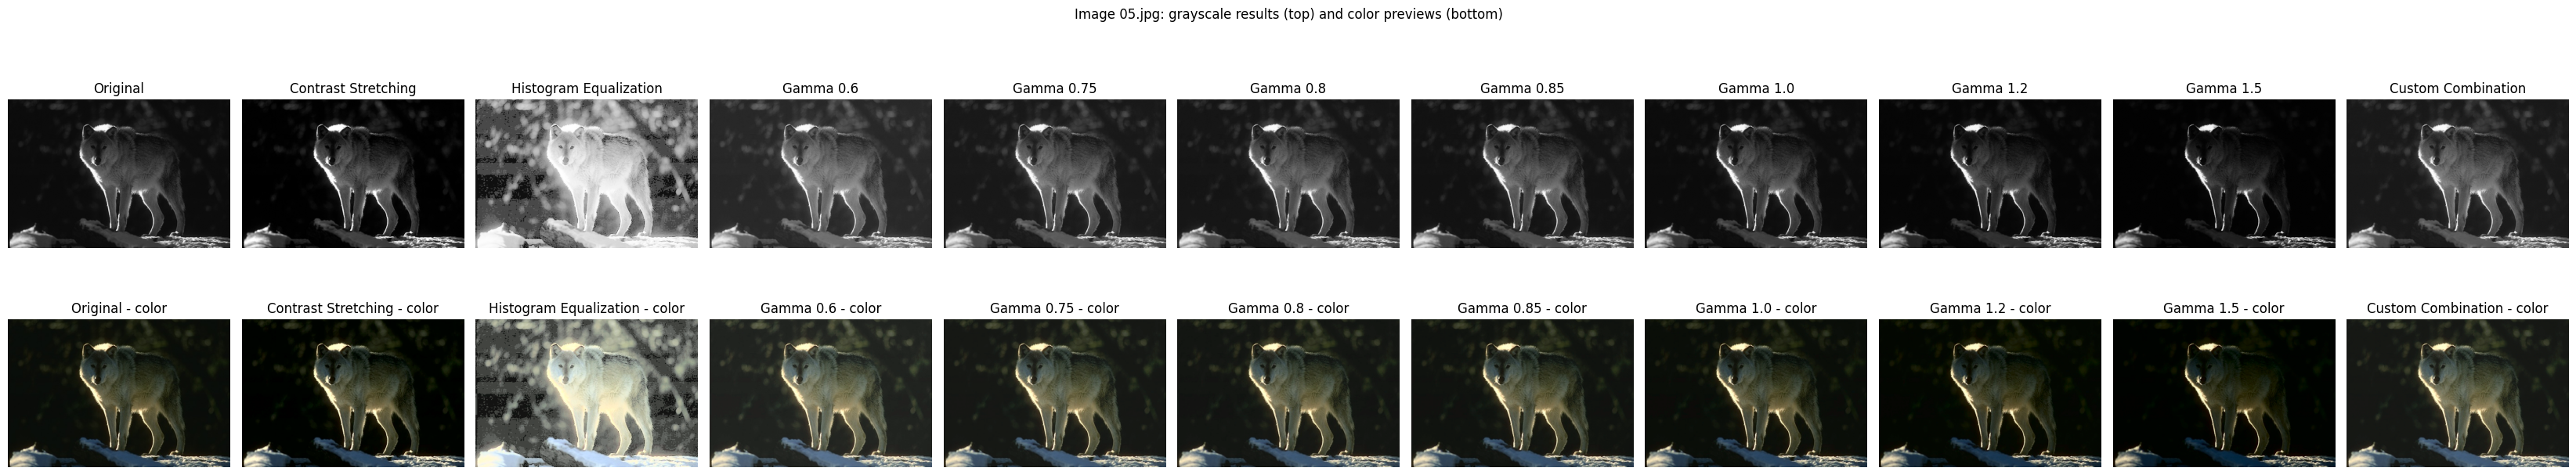

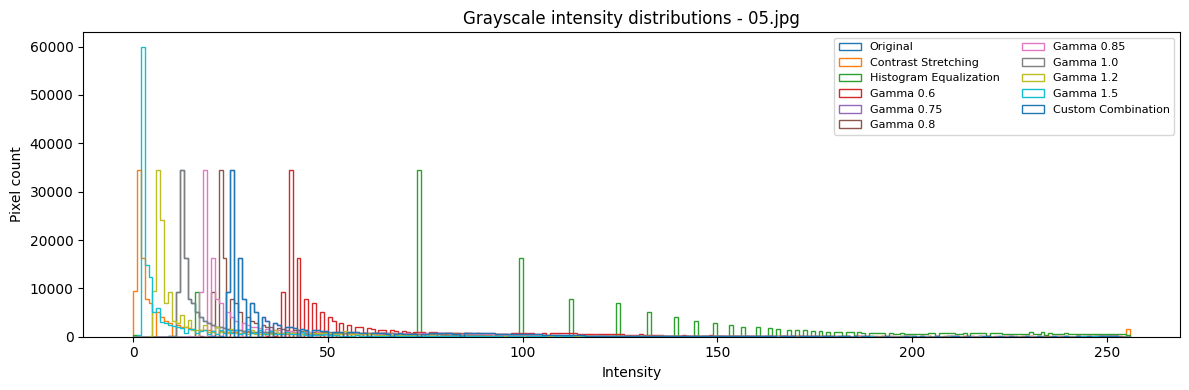

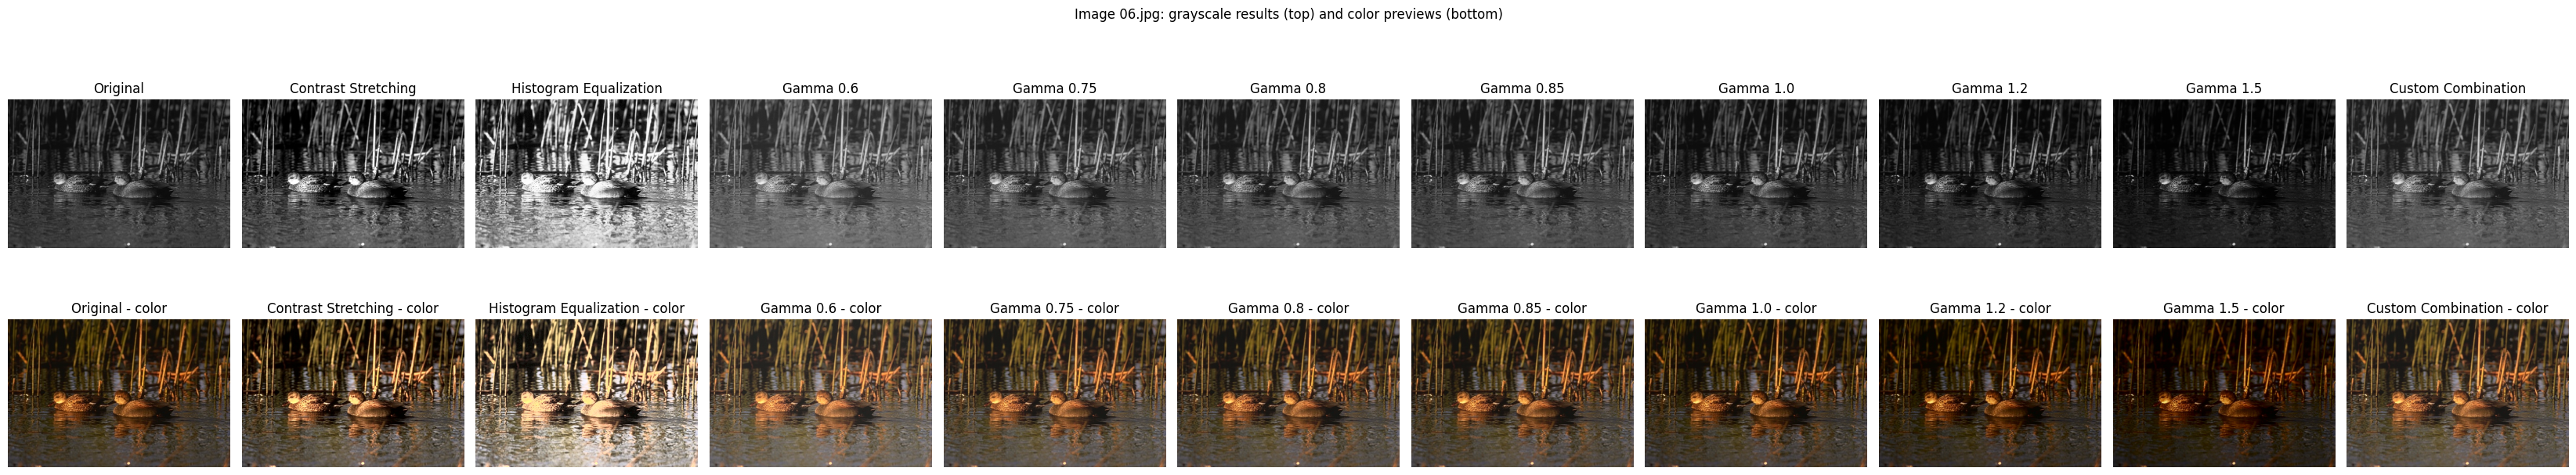

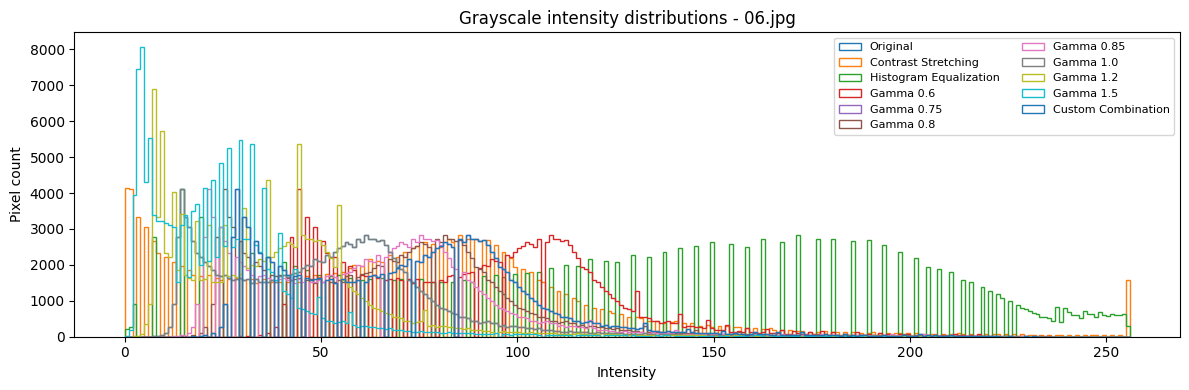

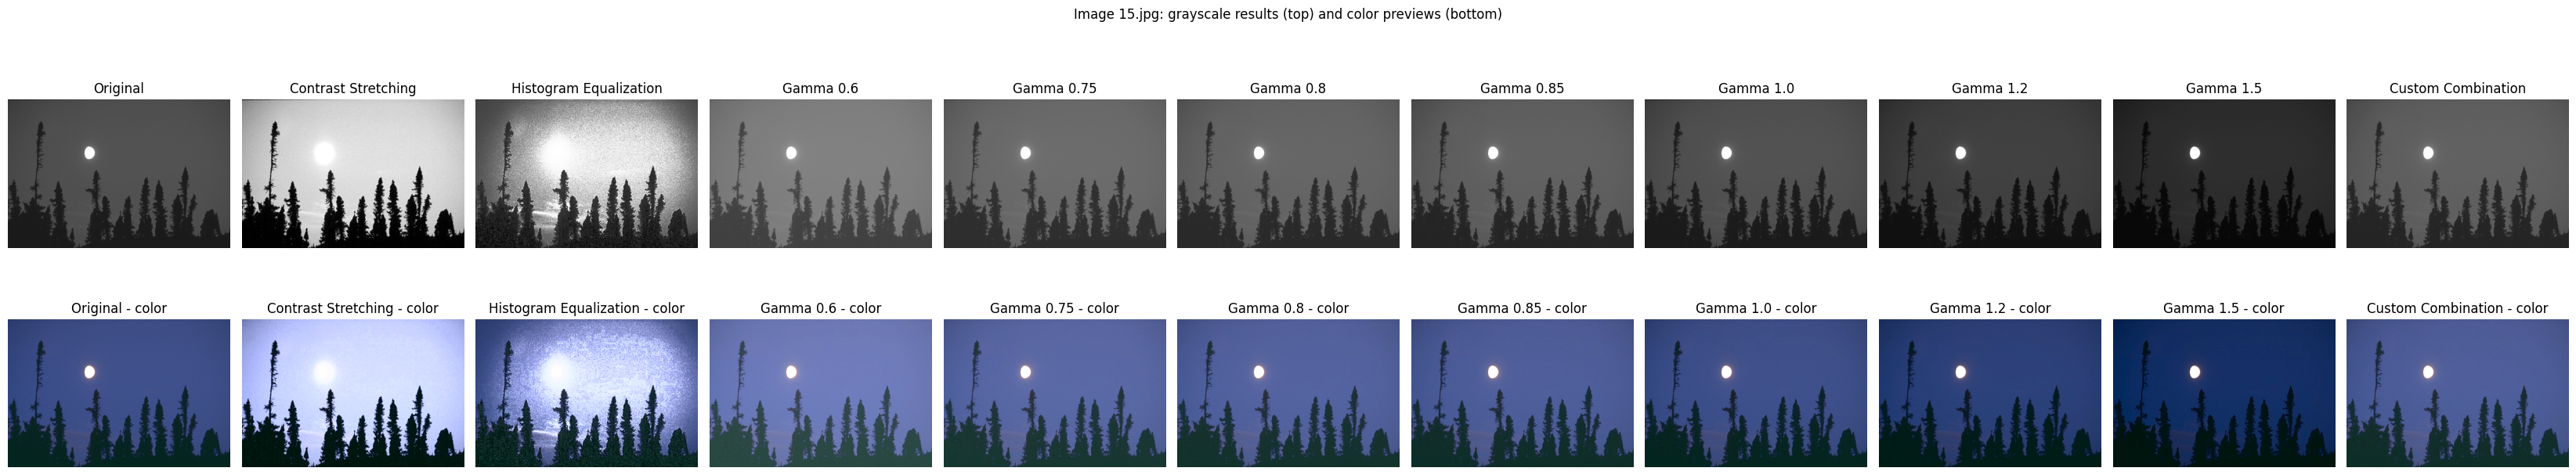

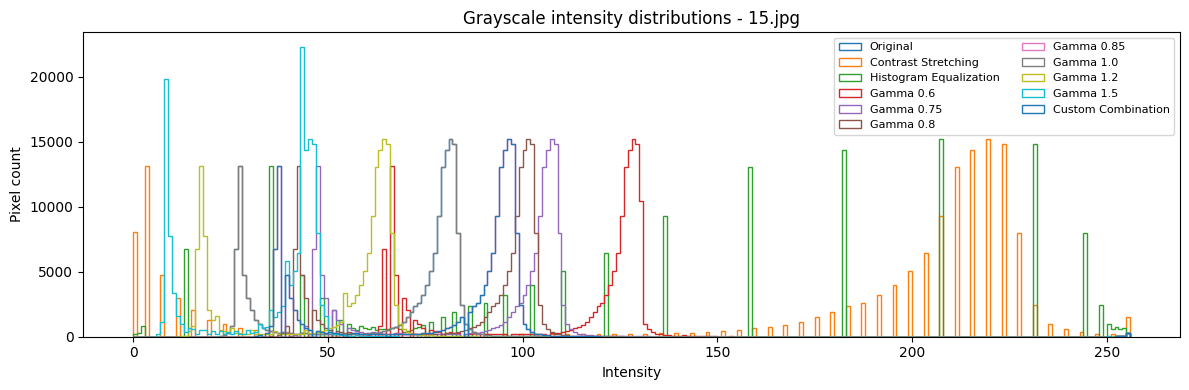

In [4]:
all_results = {}
statistics = []

for image_name in SELECTED_IMAGE_NAMES:
    image_path = IMAGE_DIR / image_name
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    color_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if gray is None or color_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")
    color_rgb = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2RGB)

    custom_steps = CUSTOM_PIPELINES.get(image_name, [])

    gamma_results = {
        f"Gamma {gamma}": gamma_transform(gray, gamma)
        for gamma in GAMMA_VALUES
    }
    gray_results = {
        "Original": gray,
        "Contrast Stretching": contrast_stretch(gray),
        "Histogram Equalization": histogram_equalization(gray, EQUALIZATION_STRENGTH),
        **gamma_results,
        "Custom Combination": apply_pipeline_gray(gray, custom_steps),
    }
    color_results = {
        "Original": color_rgb,
        "Contrast Stretching": transform_color_lightness(color_bgr, contrast_stretch),
        "Histogram Equalization": transform_color_lightness(
            color_bgr, lambda lightness: histogram_equalization(lightness, EQUALIZATION_STRENGTH)
        ),
        **{
            f"Gamma {gamma}": transform_color_lightness(
                color_bgr, lambda lightness, value=gamma: gamma_transform(lightness, value)
            )
            for gamma in GAMMA_VALUES
        },
        "Custom Combination": apply_pipeline_color(color_bgr, custom_steps),
    }
    all_results[image_name] = {"gray": gray_results, "color": color_results}

    for method_name, result in gray_results.items():
        if method_name == "Contrast Stretching":
            parameters = "low_pct=" + str(LOW_PERCENTILE) + ", high_pct=" + str(HIGH_PERCENTILE)
        elif method_name == "Histogram Equalization":
            parameters = "strength=" + str(EQUALIZATION_STRENGTH)
        elif method_name == "Custom Combination":
            parameters = str(custom_steps) if custom_steps else "empty pipeline (original image)"
        elif method_name.startswith("Gamma "):
            parameters = "gamma=" + method_name.replace("Gamma ", "")
        else:
            parameters = "none"
        statistics.append({
            "image": image_name,
            "method": method_name,
            "parameters": parameters,
            **image_metrics(result),
        })

    method_names = list(gray_results)
    fig, axes = plt.subplots(2, len(method_names), figsize=(3 * len(method_names), 7))
    for column, method_name in enumerate(method_names):
        axes[0, column].imshow(gray_results[method_name], cmap="gray", vmin=0, vmax=255)
        axes[0, column].set_title(method_name)
        axes[0, column].axis("off")
        axes[1, column].imshow(color_results[method_name])
        axes[1, column].set_title(f"{method_name} - color")
        axes[1, column].axis("off")
    fig.suptitle(f"Image {image_name}: grayscale results (top) and color previews (bottom)")
    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 4))
    for method_name, result in gray_results.items():
        ax.hist(result.ravel(), bins=256, range=(0, 256), histtype="step", label=method_name)
    ax.set(title=f"Grayscale intensity distributions - {image_name}", xlabel="Intensity", ylabel="Pixel count")
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    plt.show()

## 5. Compare the statistics

Mean intensity summarizes overall brightness. Standard deviation describes global intensity spread and is only a rough contrast indicator. These statistics do not measure whether the image looks natural or whether meaningful detail was preserved.

### What the metrics mean

Mean brightness estimates overall lightness. Standard deviation measures intensity spread, a rough global contrast indicator. Entropy measures intensity diversity and may also rise when noise becomes more visible. Clipped-pixel percentage counts values near the darkest and brightest ends (0-5 and 250-255); higher clipping can indicate lost shadow or highlight detail. Use metrics with visual previews, not as stand-alone quality scores.

In [5]:
statistics_df = pd.DataFrame(statistics)
for image_name in SELECTED_IMAGE_NAMES:
    print(f"\n{image_name}")
    display(statistics_df[statistics_df["image"] == image_name].set_index("method"))


01.jpg


,image,parameters,mean_brightness,std_intensity,entropy_bits,clipped_pixels_percent,min_intensity,max_intensity
method,,,,,,,,
Original,01.jpg,none,111.578476,44.013157,6.232853,0.707249,0,192
Contrast Stretching,01.jpg,"low_pct=1, high_pct=99",182.152634,76.675301,6.155335,4.718234,0,255
Histogram Equalization,01.jpg,strength=1,130.399658,75.130257,5.990074,4.398935,0,255
Gamma 0.6,01.jpg,gamma=0.6,150.041748,44.829159,5.876712,0.073186,0,215
Gamma 0.75,01.jpg,gamma=0.75,133.631058,45.556282,6.028828,0.123056,0,206
Gamma 0.8,01.jpg,gamma=0.8,128.676971,45.461266,6.079609,0.214377,0,203
Gamma 0.85,01.jpg,gamma=0.85,124.000725,45.250423,6.133571,0.334195,0,200
Gamma 1.0,01.jpg,gamma=1.0,111.578476,44.013157,6.232853,0.707249,0,192
Gamma 1.2,01.jpg,gamma=1.2,96.311165,41.528366,6.126157,4.209817,0,181



02.jpg


,image,parameters,mean_brightness,std_intensity,entropy_bits,clipped_pixels_percent,min_intensity,max_intensity
method,,,,,,,,
Original,02.jpg,none,126.113434,46.843040,7.378509,2.451409,4,255
Contrast Stretching,02.jpg,"low_pct=1, high_pct=99",108.969627,53.177849,7.326245,4.360075,0,255
Histogram Equalization,02.jpg,strength=1,128.426773,73.763435,7.132933,4.381448,0,255
Gamma 0.6,02.jpg,gamma=0.6,163.662125,38.198467,7.018246,2.799205,21,255
Gamma 0.75,02.jpg,gamma=0.75,147.780807,42.396580,7.192995,2.580294,11,255
Gamma 0.8,02.jpg,gamma=0.8,142.952759,43.513268,7.247708,2.580294,9,255
Gamma 0.85,02.jpg,gamma=0.85,138.424576,44.443192,7.274456,2.450114,7,255
Gamma 1.0,02.jpg,gamma=1.0,126.113434,46.843040,7.378509,2.451409,4,255
Gamma 1.2,02.jpg,gamma=1.2,110.901772,48.975437,7.327079,2.277187,1,255



05.jpg


,image,parameters,mean_brightness,std_intensity,entropy_bits,clipped_pixels_percent,min_intensity,max_intensity
method,,,,,,,,
Original,05.jpg,none,33.458546,38.579468,5.357305,0.298573,3,255
Contrast Stretching,05.jpg,"low_pct=1, high_pct=99",26.857105,45.847885,5.293231,49.653176,0,255
Histogram Equalization,05.jpg,strength=1,136.962738,64.732666,5.129408,2.359441,0,255
Gamma 0.6,05.jpg,gamma=0.6,67.627510,40.798763,5.323993,0.472147,17,255
Gamma 0.75,05.jpg,gamma=0.75,50.760143,40.598118,5.342067,0.367226,9,255
Gamma 0.8,05.jpg,gamma=0.8,46.487911,40.224674,5.346004,0.367226,7,255
Gamma 0.85,05.jpg,gamma=0.85,42.363159,40.034237,5.347728,0.295335,5,255
Gamma 1.0,05.jpg,gamma=1.0,33.458546,38.579468,5.357305,0.298573,3,255
Gamma 1.2,05.jpg,gamma=1.2,24.241760,36.518867,5.021172,6.351643,1,255



06.jpg


,image,parameters,mean_brightness,std_intensity,entropy_bits,clipped_pixels_percent,min_intensity,max_intensity
method,,,,,,,,
Original,06.jpg,none,51.575314,28.842533,6.567075,0.006477,2,255
Contrast Stretching,06.jpg,"low_pct=1, high_pct=99",67.867401,49.385452,6.467829,10.567289,0,255
Histogram Equalization,06.jpg,strength=1,129.144485,73.258186,6.405616,3.066690,0,255
Gamma 0.6,06.jpg,gamma=0.6,93.759254,31.865213,6.534026,0.005829,13,255
Gamma 0.75,06.jpg,gamma=0.75,74.204880,31.364662,6.556320,0.003238,6,255
Gamma 0.8,06.jpg,gamma=0.8,68.794472,30.933796,6.559456,0.003886,5,255
Gamma 0.85,06.jpg,gamma=0.85,63.823925,30.568153,6.559670,0.003886,4,255
Gamma 1.0,06.jpg,gamma=1.0,51.575314,28.842533,6.567075,0.006477,2,255
Gamma 1.2,06.jpg,gamma=1.2,38.278671,26.276218,6.259883,0.301812,0,255



15.jpg


,image,parameters,mean_brightness,std_intensity,entropy_bits,clipped_pixels_percent,min_intensity,max_intensity
method,,,,,,,,
Original,15.jpg,none,66.555489,24.269005,4.754357,0.279791,19,255
Contrast Stretching,15.jpg,"low_pct=1, high_pct=99",159.100372,87.484398,4.661157,14.820500,0,255
Histogram Equalization,15.jpg,strength=1,134.770111,75.445328,4.652918,3.402180,0,255
Gamma 0.6,15.jpg,gamma=0.6,111.504715,26.336323,4.699707,0.282382,53,255
Gamma 0.75,15.jpg,gamma=0.75,91.084618,25.952124,4.753992,0.281086,36,255
Gamma 0.8,15.jpg,gamma=0.8,85.331238,25.694822,4.754147,0.281086,31,255
Gamma 0.85,15.jpg,gamma=0.85,80.348694,25.702045,4.753973,0.279791,28,255
Gamma 1.0,15.jpg,gamma=1.0,66.555489,24.269005,4.754357,0.279791,19,255
Gamma 1.2,15.jpg,gamma=1.2,51.280212,22.200033,4.657541,0.275905,11,255


In [6]:
from pathlib import Path
import json

OUTPUT_DIR = PROJECT_ROOT / "1 Image Enhancement" / "outputs" / "random_five_before_after"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for image_name in SELECTED_IMAGE_NAMES:
    original_bgr = cv2.imread(str(IMAGE_DIR / image_name), cv2.IMREAD_COLOR)
    before_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    after_rgb = all_results[image_name]["color"]["Custom Combination"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(before_rgb); axes[0].set_title(f"Before: {image_name}"); axes[0].axis("off")
    axes[1].imshow(after_rgb); axes[1].set_title(f"After: {image_name}"); axes[1].axis("off")
    fig.suptitle(f"Custom pipeline: {CUSTOM_PIPELINES[image_name]}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{image_name[:2]}_before_after.png", dpi=160, bbox_inches="tight")
    plt.close(fig)
    cv2.imwrite(str(OUTPUT_DIR / f"{image_name[:2]}_enhanced.png"), cv2.cvtColor(after_rgb, cv2.COLOR_RGB2BGR))

selected_metrics = statistics_df[statistics_df.image.isin(SELECTED_IMAGE_NAMES)].copy()
selected_metrics.to_csv(OUTPUT_DIR / "selected_metrics.csv", index=False)
with (OUTPUT_DIR / "selected_pipelines.json").open("w", encoding="utf-8") as f:
    json.dump({"seed": SELECTION_SEED, "selected_images": SELECTED_IMAGE_NAMES,
               "pipelines": {name: CUSTOM_PIPELINES[name] for name in SELECTED_IMAGE_NAMES}},
              f, indent=2, ensure_ascii=False)
print(f"Saved comparisons, enhanced images, and metadata in {OUTPUT_DIR}")

Saved comparisons, enhanced images, and metadata in c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\1 Image Enhancement\outputs\random_five_before_after


## 6. How to decide which method to use

Use these as interpretation cues, not as automatic rules. Inspect the original and every result at the same display scale. The method with the largest standard deviation or widest histogram is not automatically the best.

| Method | Consider it when | Check for tradeoffs |
|---|---|---|
| Contrast Stretching | The useful intensities occupy a narrow range and you want to expand that range. | Percentile clipping can crush dark detail or wash out bright areas; check whether important shadows or highlights are lost. |
| Histogram Equalization | Global contrast is weak and detail across several intensity ranges needs stronger visibility. | It can make noise or texture more visible and may make a natural scene look harsh. |
| Gamma below 1 | The image is too dark and you want to lift mid-tones. | Bright regions can become too dominant; inspect highlights and overall naturalness. |
| Gamma above 1 | The image is too bright and you want to darken mid-tones. | Dark details can become hard to see; inspect shadows. |

### Per-image decision checklist

For each image, answer: (1) What problem do you see in the original? (2) Which output improves that problem? (3) What detail, noise, or naturalness tradeoff appears? (4) Which method and parameters best fit the goal, and what visual/statistical evidence supports the choice?